# FlexGlue Demo
To match or not to match: In this notebook we match an image pair with FlexGlue, and predict whether another pair is covisible at all.

In [1]:
# On Colab: clone the repo and install FlexGlue
from pathlib import Path

if Path.cwd().name != "FlexGlue":
    !git clone --quiet https://github.com/cvg/FlexGlue
    %cd FlexGlue
    %pip install --progress-bar off --quiet -e .
import torch

from flexglue import FlexGlue
from flexglue.utils import load_image, pack_matches, rbd, viz2d

torch.set_grad_enabled(False)
images = Path("assets")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load the matcher
FlexGlue consists of a DINOv3 backbone and a transformer that aggregates context between images.

In [ ]:
matcher = FlexGlue(n_layers=9).eval().to(device)  # release weights, with its descriptor

## Dense matching
Without keypoints, FlexGlue predicts dense correspondences in both directions and samples matches from them. The bottom row warps each image into the other one.

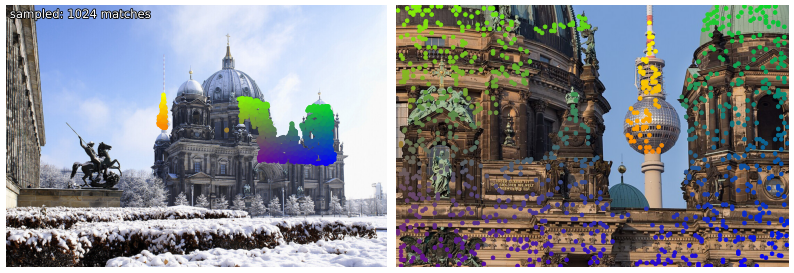

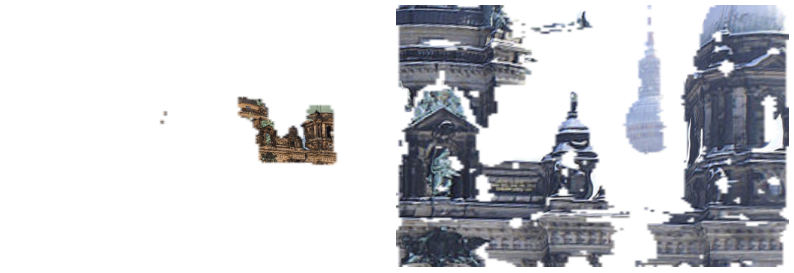

In [3]:
image0 = load_image(images / "berlin1.jpg").to(device)
image1 = load_image(images / "berlin2.jpg").to(device)

def plot_matches(pred: dict, kpts0: torch.Tensor, kpts1: torch.Tensor, title: str, lw: float = 0.2):
    matches = rbd(pack_matches(pred))["matches"]
    viz2d.plot_images([image0, image1], dpi=60)
    viz2d.plot_matches(kpts0[matches[:, 0]], kpts1[matches[:, 1]], lw=lw, ps=20)
    viz2d.add_text(0, f"{title}: {len(matches)} matches", fs=14)


inputs0 = matcher.descriptor.describe(image0)  # {features, image_size}
inputs1 = matcher.descriptor.describe(image1)

# Neither has keypoints: correspondences are sampled. coarse_stride=4 means that we get one query every 4x4 pixels.
pred = matcher.match(inputs0, inputs1, max_num_samples=1024, coarse_stride=4)
plot_matches(pred, rbd(pred)["keypoints0"], rbd(pred)["keypoints1"], "sampled", lw=0.0)
warped1 = viz2d.warp_image(image1, pred["dense_p2d0_n1"], pred["dense_valid0"], size=image0.shape[-2:])
warped0 = viz2d.warp_image(image0, pred["dense_p2d1_n0"], pred["dense_valid1"], size=image1.shape[-2:])
viz2d.plot_images([warped1, warped0], dpi=60)

## Load a keypoint detector
Use your favourite detector to find sparse keypoints. We recommend [RaCo](https://github.com/cvg/RaCo), but all detectors from [LightGlue](https://github.com/cvg/LightGlue) work (and many more).

In [ ]:
# RaCo from torch.hub, needs kornia
%pip install --quiet kornia  # for RaCo
detector = torch.hub.load("cvg/RaCo:v1.0.0", "raco", trust_repo=True, max_num_keypoints=2048)

# or LightGlue's detectors, with the latest LightGlue:
# %pip install --quiet git+https://github.com/cvg/LightGlue.git  # for ALIKED, SuperPoint, ...
# from lightglue import ALIKED, SuperPoint, SIFT
# detector = ALIKED(origin="corner")

detector = detector.eval().to(device)

## Keypoints in one image
With keypoints in image #0 only, each keypoint is matched to its predicted point in image #1.

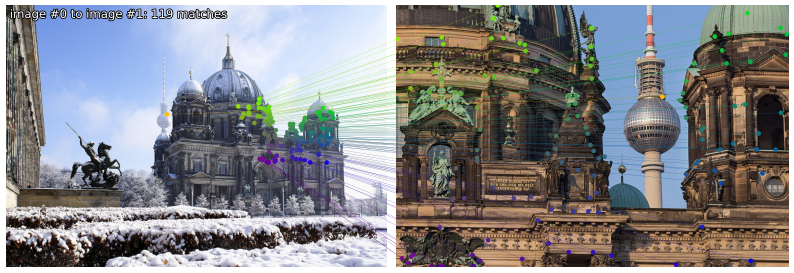

In [5]:
inputs0.update(detector.extract(image0))  # {keypoints, ...}
pred = matcher.match(inputs0, inputs1)
plot_matches(pred, rbd(pred)["keypoints0"], rbd(pred)["keypoints1"], "image #0 to image #1")

## Keypoints in both images
By default, each keypoint of both images is paired with its predicted point in the other image, and both directions are concatenated.

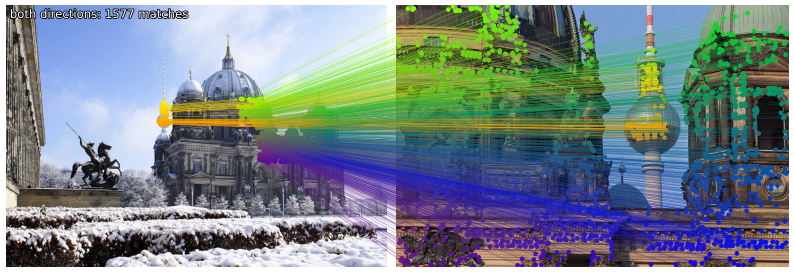

In [6]:
inputs1.update(detector.extract(image1))
pred = matcher.match(inputs0, inputs1)
plot_matches(pred, rbd(pred)["keypoints0"], rbd(pred)["keypoints1"], "both directions")

## Sparse matching
With `sparse=True`, the keypoints of both images are matched to each other with mutual nearest neighbors, as in LightGlue.

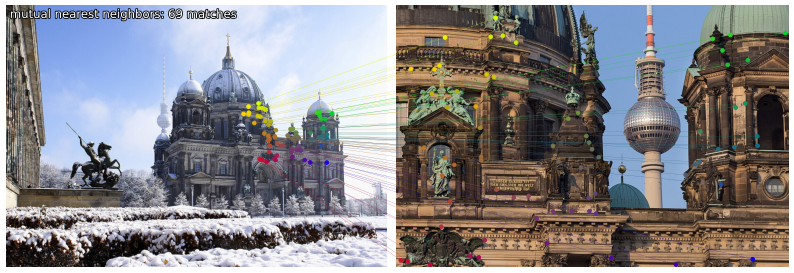

In [7]:
pred = matcher.match(inputs0, inputs1, sparse=True)
plot_matches(pred, rbd(pred)["keypoints0"], rbd(pred)["keypoints1"], "mutual nearest neighbors")

## Semi-dense matching
A regular grid of query points in image #0 is matched into image #1.

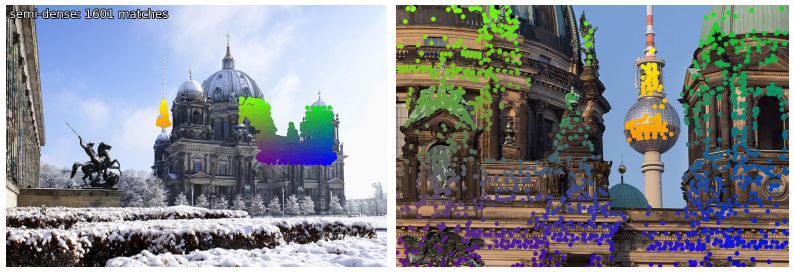

In [8]:
stride = 16  # grid pitch in pixels of image #0
w, h = inputs0["image_size"][0].tolist()
ys, xs = torch.meshgrid(
    torch.arange(stride / 2, h, stride), torch.arange(stride / 2, w, stride), indexing="ij"
)
grid0 = torch.stack([xs, ys], -1).reshape(1, -1, 2).to(device)
semi0 = {k: inputs0[k] for k in ("features", "image_size", "image")}  # no detector keys
pred = matcher.match({**semi0, "keypoints": grid0}, inputs1)
plot_matches(pred, rbd(pred)["keypoints0"], rbd(pred)["keypoints1"], "semi-dense", lw=0.0)

## Look-alike pairs
FlexGlue predicts whether two images show the same place. Here, the same facade at different places is rejected, and we avoid unnecessary compute by detecting this early.

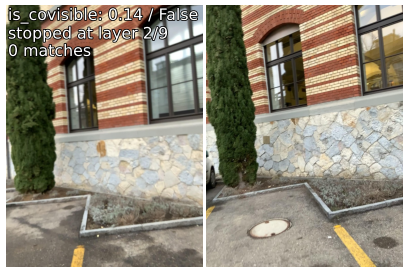

In [9]:
negative0 = load_image(images / "lamar_cab_1446.jpg").to(device)
negative1 = load_image(images / "lamar_cab_1450.jpg").to(device)
neginputs0 = {**detector.extract(negative0), **matcher.descriptor.describe(negative0)}
neginputs1 = {**detector.extract(negative1), **matcher.descriptor.describe(negative1)}

# a pair with a a too low covisibility score will be rejected and no matches will be returned. 
# early_stop_decay can be used to adjust min_covisibility over the layers. A lower value stops earlier.
pred = rbd(pack_matches(
    matcher.match(neginputs0, neginputs1, min_covisibility=0.8, early_stop_decay=0.2)
))
covis, layer, matches = pred["covisibility_score"].item(), pred["stop_layer"], pred["matches"]
viz2d.plot_images([negative0, negative1], dpi=60)
viz2d.add_text(
    0,
    f"is_covisible: {covis:.2f} / {pred['is_covisible'].item()}\n"
    f"stopped at layer {layer}/{matcher.conf.n_layers}\n"
    f"{len(matches)} matches",
    fs=19,
)